# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Saba Mahar     
- **Student ID:** 023-24-0141    
- **Section:** H
- **GitHub:** https://github.com/sabamahar304
- **Kaggle:** https://www.kaggle.com/sabamahar   
- **Dataset:** Telco Customer Churn (Kaggle)     
- **Dataset Source:** https://www.kaggle.com/code/emineyetm/telco-customer-churn     
---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
#Part0

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clean_churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Shape: (7010, 20)
Missing values: 0


In [2]:
from sklearn.model_selection import train_test_split

y = df["Churn"].map({"No": 0, "Yes": 1})
X = pd.get_dummies(df.drop("Churn", axis=1), drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5608, 30)
X_test: (1402, 30)
y_train: (5608,)
y_test: (1402,)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
#Part1

import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

t0 = time.time()
svm_raw = SVC(kernel="linear", random_state=42)
svm_raw.fit(X_train, y_train)
raw_train_time = time.time() - t0

raw_pred = svm_raw.predict(X_test)

raw_accuracy = accuracy_score(y_test, raw_pred)
raw_precision = precision_score(y_test, raw_pred)
raw_recall = recall_score(y_test, raw_pred)
raw_f1 = f1_score(y_test, raw_pred)

print("Training time (unscaled):", round(raw_train_time, 2), "seconds")
print("Accuracy:", round(raw_accuracy, 4))
print("Precision:", round(raw_precision, 4))
print("Recall:", round(raw_recall, 4))
print("F1-Score:", round(raw_f1, 4))

Training time (unscaled): 516.36 seconds
Accuracy: 0.7946
Precision: 0.6812
Recall: 0.4205
F1-Score: 0.52


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

t0 = time.time()
svm_scaled = SVC(kernel="linear", random_state=42)
svm_scaled.fit(X_train_s, y_train)
scaled_train_time = time.time() - t0

scaled_pred = svm_scaled.predict(X_test_s)

scaled_accuracy = accuracy_score(y_test, scaled_pred)
scaled_precision = precision_score(y_test, scaled_pred)
scaled_recall = recall_score(y_test, scaled_pred)
scaled_f1 = f1_score(y_test, scaled_pred)

print("Training time (scaled):", round(scaled_train_time, 2), "seconds")
print("Accuracy:", round(scaled_accuracy, 4))
print("Precision:", round(scaled_precision, 4))
print("Recall:", round(scaled_recall, 4))
print("F1-Score:", round(scaled_f1, 4))

Training time (scaled): 4.9 seconds
Accuracy: 0.8067
Precision: 0.6645
Recall: 0.5445
F1-Score: 0.5985


**Questions to answer:**

(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The biggest difference is training time. The unscaled SVM took more seconds to train than the scaled version. Accuracy and F1-score were also better after scaling, even though I didn't get any explicit warning on the unscaled run.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* SVM finds the boundary by maximizing the margin, which is a distance calculation. Without scaling, a feature like TotalCharges completely dominates that distance compared to a 0/1 dummy column.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the scaled version for every SVM from here on, since it trains almost instantly and gets better accuracy, precision, recall, and F1-score.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
#Part2

kernel_results = {}

for kernel in ["linear", "rbf", "poly"]:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)

    kernel_results[kernel] = {
        "model": model,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "Support Vectors": model.support_.shape[0]
    }

for kernel, res in kernel_results.items():
    print(kernel, {k: round(v, 4) if isinstance(v, float) else v for k, v in res.items() if k != "model"})

linear {'Accuracy': 0.8067, 'Precision': 0.6645, 'Recall': 0.5445, 'F1-Score': 0.5985, 'Support Vectors': 2586}
rbf {'Accuracy': 0.8031, 'Precision': 0.674, 'Recall': 0.496, 'F1-Score': 0.5714, 'Support Vectors': 2676}
poly {'Accuracy': 0.8024, 'Precision': 0.6895, 'Recall': 0.4609, 'F1-Score': 0.5525, 'Support Vectors': 2740}


In [6]:
kernel_comparison = pd.DataFrame({
    "Kernel": list(kernel_results.keys()),
    "Accuracy": [kernel_results[k]["Accuracy"] for k in kernel_results],
    "Precision": [kernel_results[k]["Precision"] for k in kernel_results],
    "Recall": [kernel_results[k]["Recall"] for k in kernel_results],
    "F1-Score": [kernel_results[k]["F1-Score"] for k in kernel_results],
    "Support Vectors": [kernel_results[k]["Support Vectors"] for k in kernel_results]
})

kernel_comparison

,Kernel,Accuracy,Precision,Recall,F1-Score,Support Vectors
0,linear,0.806705,0.664474,0.544474,0.598519,2586
1,rbf,0.803138,0.673993,0.495957,0.571429,2676
2,poly,0.802425,0.689516,0.460916,0.552504,2740


Best kernel on F1-score: linear


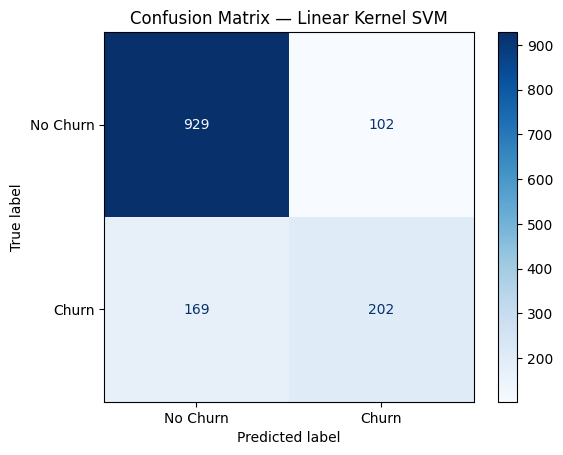

In [7]:
best_kernel = kernel_comparison.loc[kernel_comparison["F1-Score"].idxmax(), "Kernel"]
best_kernel_model = kernel_results[best_kernel]["model"]

print("Best kernel on F1-score:", best_kernel)

ConfusionMatrixDisplay.from_estimator(best_kernel_model, X_test_s, y_test, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title(f"Confusion Matrix — {best_kernel.capitalize()} Kernel SVM")
plt.show()

**Questions to answer:**

(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The linear kernel got the best F1-score ahead of RBF and poly. This surprised me a bit, since in class RBF is usually described as more powerful because it can draw curved boundaries.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The polynomial kernel used the most support vectors. A higher support-vector count means the model is relying on more points to define its boundary.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* Even though linear technically won here, Part 4 specifically asks to tune an RBF-kernel SVM with C and gamma, so I carried RBF forward as instructed. RBF's F1-score (0.571) was close to linear's (0.599).

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
#Part3

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_s)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Explained variance ratio: [0.33024725 0.12008848]
Total explained variance: 45.03 %


In [9]:
c_values = [0.01, 1, 100]
pca_models = {}

for C in c_values:
    model = SVC(kernel="rbf", C=C, random_state=42)
    model.fit(X_train_pca, y_train)
    pca_models[C] = model
    print("C =", C, "-> support vectors:", model.support_.shape[0])

C = 0.01 -> support vectors: 2978
C = 1 -> support vectors: 2631
C = 100 -> support vectors: 2603


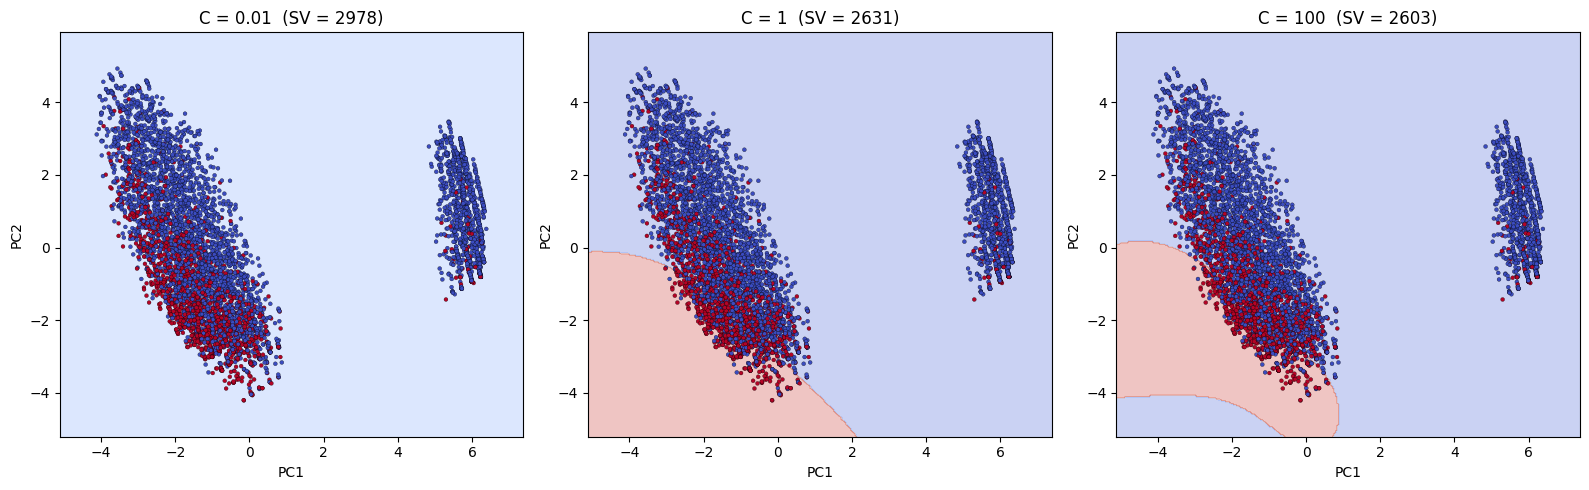

In [10]:
xx, yy = np.meshgrid(
    np.linspace(X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1, 300),
    np.linspace(X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1, 300)
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, C in zip(axes, c_values):
    model = pca_models[C]
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.2)
    ax.set_title(f"C = {C}  (SV = {model.support_.shape[0]})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Questions to answer:**

(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At C = 0.01 the boundary is very smooth and almost looks like a single straight-ish curve. As C increases to 1 and then 100, the boundary gets more wiggly and starts wrapping tightly around small pockets of points.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* Support vectors go down as C increases. This matches the theory: a small C allows more margin violations so more points end up as support vectors, while a large C penalizes violations heavily, so the model fits training points more tightly and only needs the closest points as support vectors.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C = 100 looks like it's overfitting. C = 0.01 looks like it's underfitting, mixing a lot of red and blue points together.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The 2 PCA components only capture about 45% of the total variance in the data, so a large chunk of the information the real 30-feature SVM actually uses is thrown away here. The best C in this 2-D view isn't guaranteed to be the best C for the real high-dimensional model.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
#Part4

from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)

print("Best parameters:", gs.best_params_)
print("Best cross-validated F1-score:", round(gs.best_score_, 4))

Best parameters: {'C': 10, 'gamma': 0.001}
Best cross-validated F1-score: 0.5782


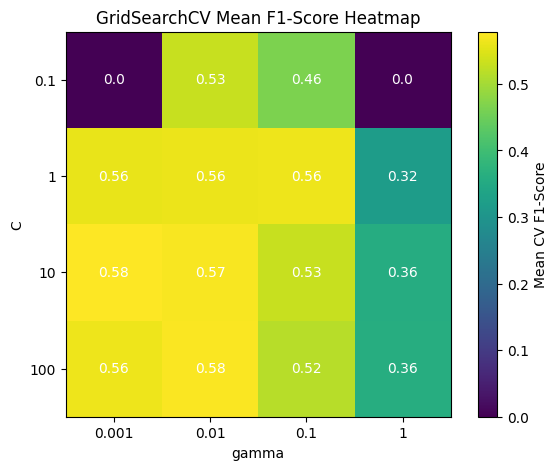

In [12]:
mean_scores = np.array(gs.cv_results_["mean_test_score"]).reshape(len(param_grid["C"]), len(param_grid["gamma"]))

plt.figure(figsize=(7, 5))
plt.imshow(mean_scores, cmap="viridis")
plt.colorbar(label="Mean CV F1-Score")
plt.xticks(range(len(param_grid["gamma"])), param_grid["gamma"])
plt.yticks(range(len(param_grid["C"])), param_grid["C"])
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("GridSearchCV Mean F1-Score Heatmap")

for i in range(mean_scores.shape[0]):
    for j in range(mean_scores.shape[1]):
        plt.text(j, i, round(mean_scores[i, j], 2), ha="center", va="center", color="white")

plt.show()

Tuned RBF SVM — Test Set Performance
Accuracy: 0.8074
Precision: 0.6747
Recall: 0.5256
F1-Score: 0.5909


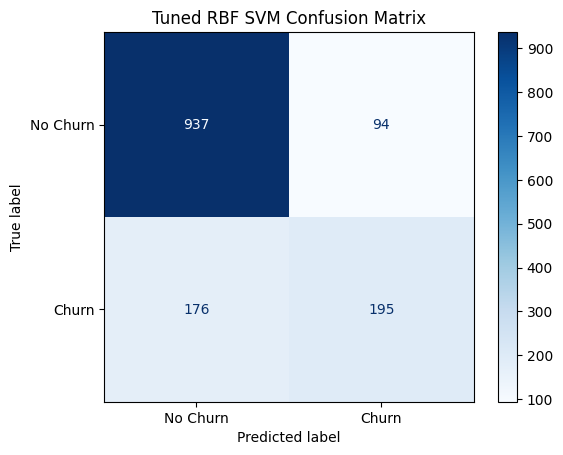

In [13]:
best_rbf = gs.best_estimator_
best_rbf_pred = best_rbf.predict(X_test_s)

tuned_accuracy = accuracy_score(y_test, best_rbf_pred)
tuned_precision = precision_score(y_test, best_rbf_pred)
tuned_recall = recall_score(y_test, best_rbf_pred)
tuned_f1 = f1_score(y_test, best_rbf_pred)

print("Tuned RBF SVM — Test Set Performance")
print("Accuracy:", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1-Score:", round(tuned_f1, 4))

ConfusionMatrixDisplay.from_predictions(y_test, best_rbf_pred, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Tuned RBF SVM Confusion Matrix")
plt.show()

**Questions to answer:**

(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* The best combination was C = 10 and gamma = 0.001, with a cross-validated F1-score of about 0.578.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* Looking at the heatmap, several combinations around C = 1-100 with small gamma so their isn't one sharp "winner" that stands far above everything else — it's more of a decent plateau. This tells me the model isn't extremely sensitive to getting the exact hyperparameters perfect, as long as I stay in that general region.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* They agreed closely — the cross-validated F1-score was about 0.578 and the test-set F1-score was about 0.591, only a small difference. A large gap would have suggested the hyperparameters were overfit to the cross-validation folds.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The untuned default RBF (Part 2) got an F1-score of 0.571, while the tuned RBF got 0.591 — a modest but real improvement, plus accuracy and precision went up slightly too.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


,Metric,class_weight=None,class_weight='balanced'
0,Accuracy,0.807418,0.708274
1,Precision,0.674740,0.470769
2,Recall,0.525606,0.824798
3,F1-Score,0.590909,0.599412


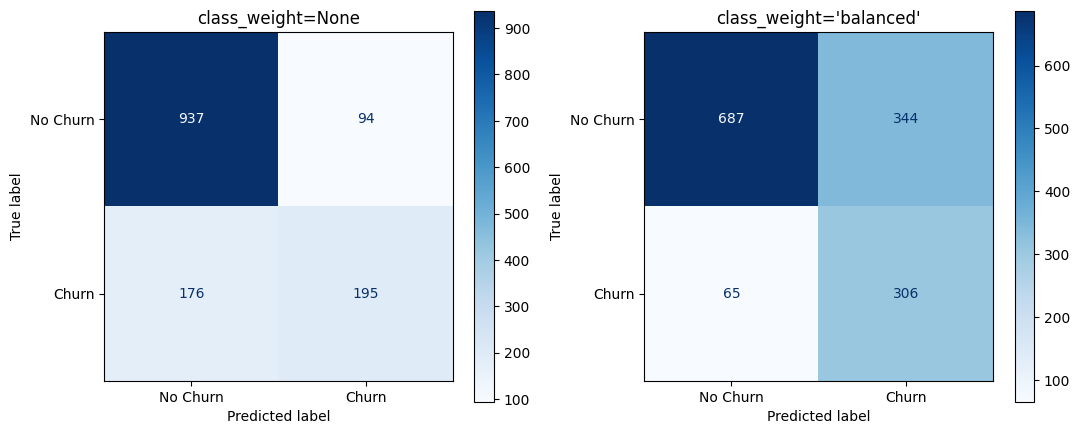

In [14]:
#Part5

best_C = gs.best_params_["C"]
best_gamma = gs.best_params_["gamma"]

svm_none = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None, probability=True, random_state=42)
svm_none.fit(X_train_s, y_train)
pred_none = svm_none.predict(X_test_s)

svm_balanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced", probability=True, random_state=42)
svm_balanced.fit(X_train_s, y_train)
pred_balanced = svm_balanced.predict(X_test_s)

class_weight_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "class_weight=None": [accuracy_score(y_test, pred_none), precision_score(y_test, pred_none), recall_score(y_test, pred_none), f1_score(y_test, pred_none)],
    "class_weight='balanced'": [accuracy_score(y_test, pred_balanced), precision_score(y_test, pred_balanced), recall_score(y_test, pred_balanced), f1_score(y_test, pred_balanced)]
})

display(class_weight_comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_none, display_labels=["No Churn", "Churn"], cmap="Blues", ax=axes[0])
axes[0].set_title("class_weight=None")
ConfusionMatrixDisplay.from_predictions(y_test, pred_balanced, display_labels=["No Churn", "Churn"], cmap="Blues", ax=axes[1])
axes[1].set_title("class_weight='balanced'")
plt.tight_layout()
plt.show()

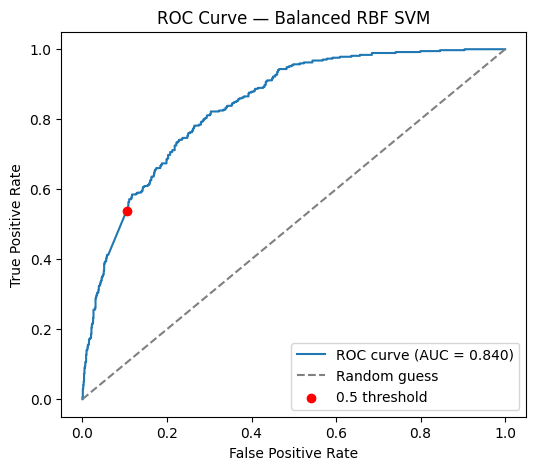

In [15]:
from sklearn.metrics import roc_curve, roc_auc_score

proba_balanced = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_balanced)
auc = roc_auc_score(y_test, proba_balanced)

default_idx = np.argmin(np.abs(thresholds - 0.5))

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.scatter(fpr[default_idx], tpr[default_idx], color="red", zorder=5, label="0.5 threshold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Balanced RBF SVM")
plt.legend()
plt.show()

**Questions to answer:**

(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Precision dropped from 0.675 to 0.471, but recall jumped from 0.526 to 0.825. F1-score stayed about the same.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing an actual churner is more costly here. Wrongly flagging a loyal customer only costs a bit of marketing effort, which is a smaller loss. So I would deploy the balanced model, since it catches 82.5% of churners compared to only 52.6% with the default version.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I had to set `probability=True` when creating the SVC model, which trains an extra internal calibration step so that `predict_proba()` works and returns probability-like scores for each class.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
#Part6

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

dt = DecisionTreeClassifier(max_depth=8, random_state=42).fit(X_train, y_train)
dt_pred = dt.predict(X_test)

rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
rf_pred = rf.predict(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
lr_pred = lr.predict(X_test_s)

knn = KNeighborsClassifier(n_neighbors=15).fit(X_train_s, y_train)
knn_pred = knn.predict(X_test_s)

final_svm_pred = pred_balanced

model_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Logistic Regression", "KNN", "SVM (RBF, tuned, balanced)"],
    "Accuracy": [accuracy_score(y_test, dt_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, lr_pred), accuracy_score(y_test, knn_pred), accuracy_score(y_test, final_svm_pred)],
    "Precision": [precision_score(y_test, dt_pred), precision_score(y_test, rf_pred), precision_score(y_test, lr_pred), precision_score(y_test, knn_pred), precision_score(y_test, final_svm_pred)],
    "Recall": [recall_score(y_test, dt_pred), recall_score(y_test, rf_pred), recall_score(y_test, lr_pred), recall_score(y_test, knn_pred), recall_score(y_test, final_svm_pred)],
    "F1-Score": [f1_score(y_test, dt_pred), f1_score(y_test, rf_pred), f1_score(y_test, lr_pred), f1_score(y_test, knn_pred), f1_score(y_test, final_svm_pred)]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.793153,0.631068,0.525606,0.573529
1,Random Forest,0.788873,0.631579,0.485175,0.548780
2,Logistic Regression,0.808845,0.673401,0.539084,0.598802
3,KNN,0.784593,0.606154,0.530997,0.566092
4,"SVM (RBF, tuned, balanced)",0.708274,0.470769,0.824798,0.599412


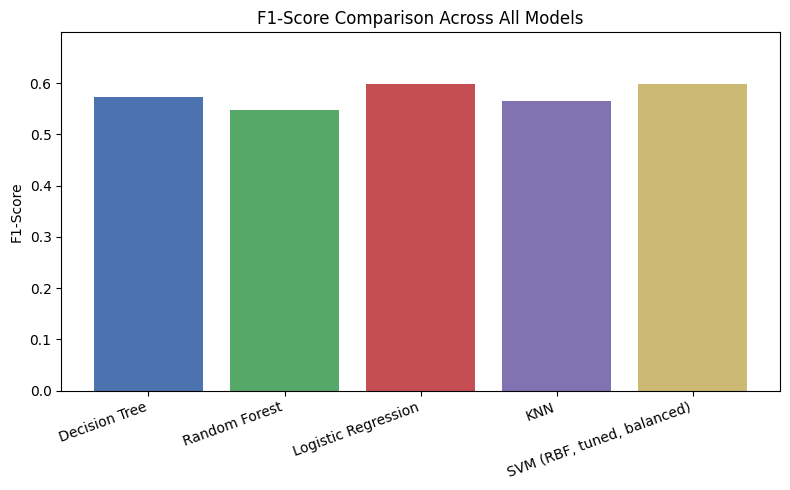

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(model_comparison["Model"], model_comparison["F1-Score"], color=["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"])
plt.ylabel("F1-Score")
plt.title("F1-Score Comparison Across All Models")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, max(model_comparison["F1-Score"]) + 0.1)
plt.tight_layout()
plt.show()

**Questions to answer:**

(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* The balanced SVM wins on both F1-score (0.599) and recall (0.825) — so yes, it's the same model on both metrics.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Yes, I think so. The grid search took about a minute, which is slower than training a single Decision Tree or Random Forest.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would recommend the balanced, tuned RBF SVM. It has the highest F1-score (0.599) of all five .

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
#Part7

svm_predictions = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": final_svm_pred,
    "Predicted_Churn_Probability": proba_balanced
})

svm_predictions.to_csv("svm_predictions.csv", index=False)

print("Saved svm_predictions.csv — shape:", svm_predictions.shape)
svm_predictions.head()

Saved svm_predictions.csv — shape: (1402, 3)


,True_Label,Predicted_Label,Predicted_Churn_Probability
0,0,1,0.500000
1,0,0,0.072953
2,0,0,0.094008
3,0,1,0.463939
4,0,1,0.433900


**Executive Summary**

I chose the tuned RBF-kernel SVM with `class_weight='balanced'` (C=10, gamma=0.001) as my final model. I accepted this trade-off deliberately in Part 5, because for a telecom company, missing a real churner is far more expensive than wasting a retention offer on a loyal customer. Across all five models tested (Decision Tree, Random Forest, Logistic Regression, KNN, SVM), this balanced SVM had the best F1-score and by far the best recall, even though plain Logistic Regression had a slightly better accuracy. One limitation of this analysis is that everything comes from a single 80/20 train-test split, so the exact numbers could shift a bit with a different split or with cross-validation.

**Final Reflection**

(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising thing was that a plain linear kernel beat RBF and polynomial kernels in Part 2 because I expected RBF to win by default.

(b) If you had one more hour, what would you try next?

*Your answer:* I would not try anything else because it is already enough for a week as i have other courses too.